
# Milestone 2: The SVD and Rank-k Approximation

In this notebook, I use singular value decomposition
(SVD) to see how images can be compressed. I look at
the singular values, compare different rank-k
approximations, and see how the image changes as
k increases.


## 1. Load the Image

(512, 512) float64


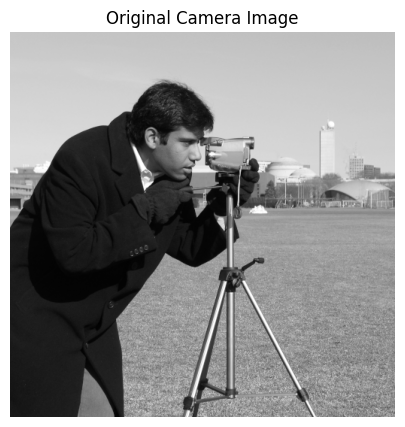


The image is a 512 by 512 grayscale matrix. I
converted it to float so the pixel calculations
work correctly without wrapping around.


## 2. Compute and Check the SVD

U: (512, 512)
s: (512,)
Vt: (512, 512)
Rebuild correctly? True
Largest error: 2.503952600818593e-11



The SVD splits the image into U, the singular
values, and Vt. When I multiply them together,
I get the original image back. The small error
is caused by rounding in the calculations.


## 3. Inspect the Singular Values

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


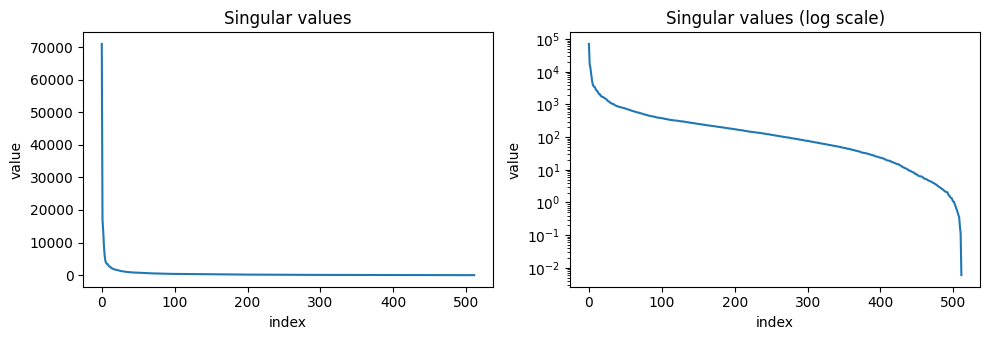


The singular values get smaller as the index
increases. The first few values are much larger
than the others, so they contain most of the
important information in the image. The log
scale makes the smaller values easier to see.


## 4. Make a Rank-k Approximation

Rank of A_10: 10
k = 512 gives A back? True
Singular values of stripes: [2.8284 0.     0.     0.    ]



The rank-k approximation keeps only the first
k singular values and their matching vectors.
When k is 10, the matrix has rank 10. When k
is 512, the whole image is reconstructed.

The stripes example only has one nonzero
singular value, which means it has rank 1.


## 5. Compare Compressed Images

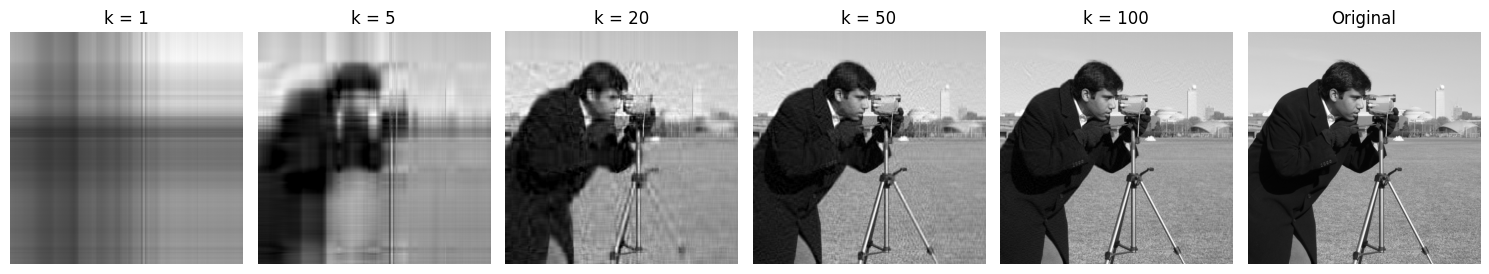


As k gets larger, the image becomes clearer.
At k = 1, most of the details are missing.
At k = 20, the image is recognizable. By
k = 100, it looks much closer to the original.

This shows how SVD can be used to compress
an image while keeping its important details.



**Why this works:** The Eckart-Young theorem
says that the rank-k approximation is the
closest rank-k matrix to the original matrix
using the Frobenius norm.

$$
\|A-A_k\|_F =
\sqrt{\sigma_{k+1}^2+\sigma_{k+2}^2+\cdots}
$$


## Exercise 1: Singular Values

M transpose times M:
[[25. 20.]
 [20. 25.]]
Eigenvalues: [ 5. 45.]
Singular values: [6.70820393 2.23606798]
SVD check: [6.70820393 2.23606798]



First, I found the matrix:

$$
M^TM =
\begin{bmatrix}
25 & 20 \\
20 & 25
\end{bmatrix}
$$

The eigenvalues are 45 and 5. I took
the square roots to find the singular
values:

$$
\sigma_1 = 3\sqrt{5} \approx 6.7082
$$

$$
\sigma_2 = \sqrt{5} \approx 2.2361
$$

These values match the results from
Python's SVD function.

Changing the signs of both corresponding
singular vectors does not change their
outer product because the two negative
signs cancel out.


## Exercise 2: Approximation Error

... (2 outputs left out)

## Exercise 3: My Photograph


For this exercise, I used a photograph
to compare different rank-k approximations.


Upload your photograph below.


Saving wp7395312.jpg to wp7395312 (1).jpg
Photograph shape: (480, 768)
Photograph data type: float64


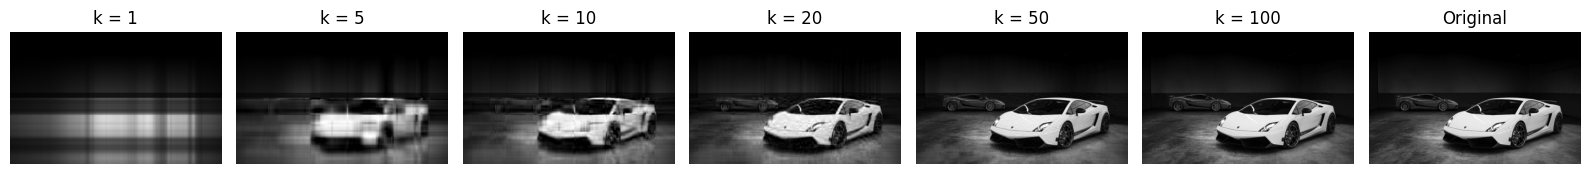


The photograph starts out blurry at the
smaller rank values. As k increases, more
details appear and it looks more like
the original.

The smallest recognizable rank depends
on the amount of detail in the photograph.


Look at the images above.
Enter the smallest k where you can recognize the photo.
Choose from: [1, 5, 10, 20, 50, 100]
Smallest recognizable k: 5, 10, 20, 50, 100
Please enter a number.
Smallest recognizable k: 5



**Exercise 3 Result**

The smallest rank where I could recognize
my photograph was **k = 5**.

As k increased, the image became clearer
and looked more like the original.

My result may be different from the camera
image because photographs have different
amounts of detail, contrast, and patterns.


## Conclusion


SVD allows an image to be compressed by
keeping fewer singular values.

Using a small k loses more details but
requires less information. Using a larger
k makes the approximation look closer to
the original image.

This shows the tradeoff between image
compression and image quality.



Milestone 2 calculations completed!
compress.py was created successfully.


In [2]:


# MATH 344L - Milestone 2
# The SVD and Rank-k Approximation
# Project 1: Image Compression with the SVD

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from PIL import Image
from IPython.display import display, Markdown
from google.colab import files
import io

# ============================================
# INTRODUCTION
# ============================================

display(Markdown("""
# Milestone 2: The SVD and Rank-k Approximation

In this notebook, I use singular value decomposition
(SVD) to see how images can be compressed. I look at
the singular values, compare different rank-k
approximations, and see how the image changes as
k increases.
"""))

# ============================================
# 1. LOAD THE IMAGE
# ============================================

display(Markdown("## 1. Load the Image"))

A = data.camera().astype(float)

print(A.shape, A.dtype)

plt.figure(figsize=(6, 5))
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Original Camera Image")
plt.axis("off")
plt.show()

display(Markdown("""
The image is a 512 by 512 grayscale matrix. I
converted it to float so the pixel calculations
work correctly without wrapping around.
"""))

# ============================================
# 2. COMPUTE AND CHECK THE SVD
# ============================================

display(Markdown("## 2. Compute and Check the SVD"))

U, s, Vt = np.linalg.svd(A, full_matrices=False)

print("U:", U.shape)
print("s:", s.shape)
print("Vt:", Vt.shape)

A_back = (U * s) @ Vt

print("Rebuild correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

display(Markdown("""
The SVD splits the image into U, the singular
values, and Vt. When I multiply them together,
I get the original image back. The small error
is caused by rounding in the calculations.
"""))

# ============================================
# 3. INSPECT THE SINGULAR VALUES
# ============================================

display(Markdown("## 3. Inspect the Singular Values"))

print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:",
      round(s[49], 1),
      round(s[199], 1),
      round(s[-1], 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

ax1.plot(s)
ax1.set(
    title="Singular values",
    xlabel="index",
    ylabel="value"
)

ax2.semilogy(s)
ax2.set(
    title="Singular values (log scale)",
    xlabel="index",
    ylabel="value"
)

plt.tight_layout()
plt.show()

display(Markdown("""
The singular values get smaller as the index
increases. The first few values are much larger
than the others, so they contain most of the
important information in the image. The log
scale makes the smaller values easier to see.
"""))

# ============================================
# 4. MAKE A RANK-K APPROXIMATION
# ============================================

display(Markdown("## 4. Make a Rank-k Approximation"))

def rank_k_approx(A, k):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= len(s):
        raise ValueError("k must be an integer between 1 and min(A.shape)")
    return (U[:, :k] * s[:k]) @ Vt[:k, :]

A10 = (U[:, :10] * s[:10]) @ Vt[:10, :]

print("Rank of A_10:", np.linalg.matrix_rank(A10))
print("k = 512 gives A back?",
      np.allclose(A_back, A))

stripes = np.outer(
    [1, 0, 1, 0],
    [1, 1, 1, 1]
).astype(float)

print("Singular values of stripes:",
      np.round(np.linalg.svd(
          stripes, compute_uv=False
      ), 4))

display(Markdown("""
The rank-k approximation keeps only the first
k singular values and their matching vectors.
When k is 10, the matrix has rank 10. When k
is 512, the whole image is reconstructed.

The stripes example only has one nonzero
singular value, which means it has rank 1.
"""))

# ============================================
# 5. COMPARE COMPRESSED IMAGES
# ============================================

display(Markdown("## 5. Compare Compressed Images"))

ks = [1, 5, 20, 50, 100]

fig, axes = plt.subplots(
    1, len(ks) + 1,
    figsize=(15, 3)
)

for ax, k in zip(axes, ks):
    Ak = (U[:, :k] * s[:k]) @ Vt[:k, :]
    Ak = np.clip(Ak, 0, 255)

    ax.imshow(
        Ak,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(
    A,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[-1].set_title("Original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

display(Markdown("""
As k gets larger, the image becomes clearer.
At k = 1, most of the details are missing.
At k = 20, the image is recognizable. By
k = 100, it looks much closer to the original.

This shows how SVD can be used to compress
an image while keeping its important details.
"""))

display(Markdown(r"""
**Why this works:** The Eckart-Young theorem
says that the rank-k approximation is the
closest rank-k matrix to the original matrix
using the Frobenius norm.

$$
\|A-A_k\|_F =
\sqrt{\sigma_{k+1}^2+\sigma_{k+2}^2+\cdots}
$$
"""))

# ============================================
# EXERCISE 1
# ============================================

display(Markdown("## Exercise 1: Singular Values"))

M = np.array([
    [3, 0],
    [4, 5]
], dtype=float)

MtM = M.T @ M

eigenvalues = np.linalg.eigvalsh(MtM)
singular_values = np.sqrt(eigenvalues)[::-1]

print("M transpose times M:")
print(MtM)

print("Eigenvalues:", eigenvalues)
print("Singular values:", singular_values)
print("SVD check:",
      np.linalg.svd(M, compute_uv=False))

display(Markdown(r"""
First, I found the matrix:

$$
M^TM =
\begin{bmatrix}
25 & 20 \\
20 & 25
\end{bmatrix}
$$

The eigenvalues are 45 and 5. I took
the square roots to find the singular
values:

$$
\sigma_1 = 3\sqrt{5} \approx 6.7082
$$

$$
\sigma_2 = \sqrt{5} \approx 2.2361
$$

These values match the results from
Python's SVD function.

Changing the signs of both corresponding
singular vectors does not change their
outer product because the two negative
signs cancel out.
"""))

# ============================================
# EXERCISE 2
# ============================================

display(Markdown("## Exercise 2: Approximation Error"))

A20 = (U[:, :20] * s[:20]) @ Vt[:20, :]

actual_error = np.linalg.norm(A - A20)

predicted_error = np.sqrt(
    np.sum(s[20:] ** 2)
)

print("Actual error:", actual_error)
print("Predicted error:", predicted_error)

print("Do they agree?",
      np.allclose(actual_error, predicted_error))

display(Markdown("""
The actual error and predicted error are
almost exactly the same. This agrees with
the Eckart-Young theorem.

The singular values after the first 20
represent the information lost when the
image is approximated using rank 20.
"""))

# ============================================
# EXERCISE 3
# ============================================

display(Markdown("## Exercise 3: My Photograph"))

display(Markdown("""
For this exercise, I used a photograph
to compare different rank-k approximations.
"""))

print("Upload your photograph below.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No photograph was uploaded.")

filename = next(iter(uploaded))

img = Image.open(
    io.BytesIO(uploaded[filename])
).convert("L")

# Resize large photographs to reduce runtime
img.thumbnail((768, 768))

photo = np.array(img).astype(float)

print("Photograph shape:", photo.shape)
print("Photograph data type:", photo.dtype)

Up, sp, Vtp = np.linalg.svd(
    photo,
    full_matrices=False
)

photo_ks = [
    k for k in [1, 5, 10, 20, 50, 100]
    if k <= len(sp)
]

fig, axes = plt.subplots(
    1,
    len(photo_ks) + 1,
    figsize=(16, 3.5)
)

for ax, k in zip(axes, photo_ks):

    compressed = (
        Up[:, :k] * sp[:k]
    ) @ Vtp[:k, :]

    compressed = np.clip(
        compressed, 0, 255
    )

    ax.imshow(
        compressed,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(
    photo,
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[-1].set_title("Original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

display(Markdown("""
The photograph starts out blurry at the
smaller rank values. As k increases, more
details appear and it looks more like
the original.

The smallest recognizable rank depends
on the amount of detail in the photograph.
"""))

# Ask for the actual observed result
print("Look at the images above.")
print("Enter the smallest k where you can recognize the photo.")
print("Choose from:", photo_ks)

while True:
    try:
        smallest_k = int(input("Smallest recognizable k: "))
        if smallest_k in photo_ks:
            break
        print("Please choose one of:", photo_ks)
    except ValueError:
        print("Please enter a number.")

display(Markdown(
    f"""
**Exercise 3 Result**

The smallest rank where I could recognize
my photograph was **k = {smallest_k}**.

As k increased, the image became clearer
and looked more like the original.

My result may be different from the camera
image because photographs have different
amounts of detail, contrast, and patterns.
"""
))

# ============================================
# CREATE COMPRESS.PY
# ============================================

compress_code = '''import numpy as np

def rank_k_approx(A, k):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= len(s):
        raise ValueError("k must be an integer between 1 and min(A.shape)")
    return (U[:, :k] * s[:k]) @ Vt[:k, :]
'''

with open("compress.py", "w") as f:
    f.write(compress_code)

# ============================================
# CONCLUSION
# ============================================

display(Markdown("## Conclusion"))

display(Markdown("""
SVD allows an image to be compressed by
keeping fewer singular values.

Using a small k loses more details but
requires less information. Using a larger
k makes the approximation look closer to
the original image.

This shows the tradeoff between image
compression and image quality.
"""))

print()
print("Milestone 2 calculations completed!")
print("compress.py was created successfully.")

